# Companies House Analysis

This notebook explores a sample of Companies House data to find insights that could help BDO identify potential new clients and better understand its existing client population.

**Questions I aimed to answer:**

- **Data Profiling:** What do the companies in the sample look like in terms of age, size, sector and location?
- **Finding potential clients (Prospecting):** Which active companies file full or group accounts, what type of organisation are they, and which BDO office is geographically closest?
- **Risk and opportunities:** How do active and non-active companies differ in overdue filings, insolvency history and outstanding charges? Which active companies operate in sectors highlighted by external research, and what potential service opportunities might this suggest?

**How this notebook is organised:** it follows the steps I took: researching the context and data, checking data quality and cleaning where needed, investigating each line of enquiry, and finishing with what I would do next.

## Setting up the notebook

In [1]:
import pandas as pd
import plotly.express as px

# Save charts as images so they show on GitHub and nbviewer
import plotly.io as pio
pio.renderers.default = "png"

profiles = pd.read_excel("Dataset.xlsx", sheet_name="company profiles")
officers = pd.read_excel("Dataset.xlsx", sheet_name="company officers")
charges = pd.read_excel("Dataset.xlsx", sheet_name="company charges")

# Make a copy of each sheet I can clean and modify
df_prof = profiles.copy()
df_off = officers.copy()
df_char = charges.copy()

# show every column so there's no "..." in the middle
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)  # don't wrap or truncate to a set width
pd.set_option("display.max_colwidth", None)  # show full text inside cells

# Colours used in every chart
BDO_BLUE = "#204399"
BDO_RED = "#ec1b3c"
BLUE_LIGHT = "#7D9BE0"   # pastel blue
RED_LIGHT = "#F4889A"    # pastel red

# 1 Contextual research and notes

Before working with the data, I decided to research what Companies House is, what each of the three sheets contains, and who BDO is, so that my analysis asks questions that matter to BDO.

## 1.1 What is Companies House?

Companies House is the UK's official register of limited companies. It registers and dissolves companies, and makes the information they file (such as their accounts, activities and directors) available to the public.

The data can be accessed through the website, bulk downloads or a REST API. The API lets you pull company data automatically.

It is registered information, not a full picture of a company's financial or commercial performance, so other sources would be needed for a fuller view.

## 1.2 Company Profiles

Company Profiles provide the main information about each organisation in the dataset. They include information such as the company's identity, legal status, company type, jurisdiction, registered address, industry, and its filing and accounting position. In the Companies House API documentation, the company profile is the resource that holds a company's basic information, looked up by its company number.

It gives the core context for a company, such as where it is based, what it does and its current status. It can also contain indicators such as overdue accounts, previous company names and whether charges are recorded against the company. That's why I used the profiles sheet as my starting point.

## 1.3 Company Officers

Company Officers provides information about the people and organisations formally appointed to a company, such as directors and secretaries. The data includes their roles, appointment dates, resignation dates and other details where available.

It shows who runs a company and how its leadership changes over time, and can show people who hold appointments at several companies.

## 1.4 Company Charges

Company Charges records loans and other financial arrangements where a lender has a legal claim over some of a company's assets if it fails to meet its financial obligations.

The data shows when these arrangements were created, who they involve, what assets are covered, and whether the charge is still outstanding or has been satisfied.

It shows a company's secured borrowing. An outstanding charge doesn't mean a company is in difficulty, though, so I wouldn't use it on its own to judge financial health.

## 1.5 Who BDO is, and what that means for this analysis

The data is only useful if the questions I ask of it are aligned to how BDO works, who its clients are, where it operates and which services it sells.

### How BDO works

- **BDO LLP is the UK and Ireland member firm of the BDO international network.** It sells four main service lines: Audit, Tax, Deals, and Consulting, Risk & Outsourcing. After merging with BDO Ireland in July 2026, it has revenue of nearly £1.1bn, about 8,500 people and 19 offices across the UK and Ireland.
- **Its main clients are the mid-market**, which BDO defines as businesses with revenue of £10m to £500m. BDO calls these businesses "the UK's economic engine": its Mid-Market Manifesto (July 2026) counts 41,849 of them, employing 11.1 million people.
- **BDO also has teams for other kinds of client.** In 2020 it became the largest auditor of London-listed companies by number of audit clients (310), and it has one of the largest specialist Not for Profit teams in the profession (charities, education, social housing and membership bodies).
- **It works with companies in difficulty as well as growing ones.** Its Business Restructuring team offers turnaround and refinancing advice, independent business reviews and formal insolvency appointments.
- **It is investing in data.** In July 2026 BDO UK announced a partnership with MindBridge to expand its use of AI analytics across its audit practice, so data skills are part of how BDO delivers its core service.

### Where BDO operates

- **Offices:** London, Birmingham, Bristol, Cambridge, Edinburgh, Gatwick, Glasgow, Guildford, Ipswich, Leeds, Liverpool, Manchester, Nottingham, Reading, Southampton and Northern Ireland in the UK, plus Dublin and Limerick in Ireland since the merger.
- **The mid-market is growing strongly in the regions.** Over the last year, the number of mid-market businesses grew faster than the 4.4% UK average in the South West (+6%), East of England (+5.4%), Scotland (+5.1%) and North West (+4.7%), all regions where BDO has offices.

### Lines of enquiry for this notebook

| External research | Line of enquiry |
|---|---|
| The mid-market is defined by revenue (£10m to £500m). | Companies House data has no revenue figures, so what can be used as an indicator for company size? |
| BDO has separate teams for private, listed and not-for-profit clients. | What types of organisations are in the sample, and which BDO teams might be relevant to them? |
| The regional mid-market is growing faster than the wider market. | Where are potential clients located, and how are they distributed between London and regional offices? |
| BDO's Business Restructuring team works with companies experiencing financial difficulty. | Which companies show potential warning signs, such as overdue filings, insolvency history or outstanding charges? What further checks would be needed?|
| FraudTrack 2026 reports £171m of fraud losses in finance and insurance, the largest of the three sector figures it gives; BDO's football report finds that 90% of clubs in the top four English football leagues expect losses for 2025; its retail tracker reports the weakest September for sales in seven years (excluding the pandemic). | Does the sample include active companies in these broad sectors, and could external research point to potential BDO service opportunities? |

**Sources:**
- [BDO UK and BDO Ireland complete merger](https://www.bdo.co.uk/en-gb/news/2026/bdo-uk-and-bdo-ireland-complete-merger)
- [Mid-Market Manifesto, July 2026](https://www.bdo.co.uk/getmedia/c22ae700-8820-4b9d-b954-3971c63ba923/Mid-market-manifesto-July-2026.pdf)
- [Regional businesses drive mid-market expansion](https://www.bdo.co.uk/en-gb/news/2026/regional-businesses-drive-mid-market-expansion-but-targeted-support-required-to-maximise-growth)
- [BDO Not for Profit](https://www.bdo.co.uk/en-gb/industries/not-for-profit)
- [BDO becomes largest auditor of listed UK firms (City AM, 2020)](https://www.cityam.com/bdo-becomes-largest-auditor-of-listed-uk-firms/)
- [BDO Business Restructuring services](https://www.bdo.co.uk/en-gb/services/advisory/business-restructuring/business-restructuring-services)
- [BDO UK and MindBridge partnership](https://www.bdo.co.uk/en-gb/news/2026/bdo-uk-and-mindbridge-partner-to-accelerate-data-driven-audit)
- [BDO UK locations](https://www.bdo.co.uk/en-gb/locations)
- [FraudTrack 2026](https://www.bdo.co.uk/en-gb/news/2026/bdos-fraudtrack-report-5-5bn-lost-to-fraud-in-2025)
- [Football finance report](https://www.bdo.co.uk/en-gb/news/2026/90-of-professional-football-clubs-expect-to-report-financial-losses-for-2025)
- [Retail sales, September 2026](https://www.bdo.co.uk/en-gb/news/2026/retailers-call-for-budget-support-as-september-sales-hit-seven-year-low)

# 2 Exploratory Analysis

With the help of AI, I made a data dictionary that matched column names to the relevant Companies House API documentation to understand what each column means. I then reviewed the descriptions against the documentation, identified deprecated fields and their replacements, and flagged columns without a clear match rather than guessing their meaning.

I also highlighted the columns I thought would be most useful for my analysis, and kept the full dictionary as a reference.

## 2.1 Shape of the data

I started by checking how many rows and columns each sheet has.

In [2]:
# Create a summary table showing the size of each sheet
# shape[0] = number of rows, shape[1] = number of columns

shape_summary = pd.DataFrame(
    [
        {
            "sheet": "profiles",
            "rows": df_prof.shape[0],
            "columns": df_prof.shape[1],
            "total values": df_prof.shape[0] * df_prof.shape[1],
        },
        {
            "sheet": "officers",
            "rows": df_off.shape[0],
            "columns": df_off.shape[1],
            "total values": df_off.shape[0] * df_off.shape[1],
        },
        {
            "sheet": "charges",
            "rows": df_char.shape[0],
            "columns": df_char.shape[1],
            "total values": df_char.shape[0] * df_char.shape[1],
        },
    ]
)
display(shape_summary)

,sheet,rows,columns,total values
0,profiles,1027,79,81133
1,officers,236,37,8732
2,charges,595,33,19635


**Findings:** The Profiles sheet contains 1,027 rows, compared with 236 Officer rows and 595 Charge rows. These differences may reflect different levels of detail: Profiles should hold one record per company, whereas Officers and Charges can hold several records for a single company.

**Next:** Check company number coverage, duplicate records and the number of unique companies in each sheet before drawing conclusions.

## 2.2 Initial data exploration

Next, I checked how many distinct companies each sheet has and whether the company numbers match, to see if the sheets can be joined.

In [3]:
print("How many distinct companies are in each sheet?")
# nunique() counts different company numbers, ignoring repeats
print("Profiles rows:", len(df_prof), "-> distinct companies:", df_prof["company_number"].nunique())
print("Officers rows:", len(df_off), "-> distinct companies:", df_off["company_number"].nunique())
print("Charges rows:", len(df_char), "-> distinct companies:", df_char["company_number"].nunique())
print()

print("Is company_number unique in the profiles sheet?")
# True would mean exactly one row per company
print("company_number unique in profiles:", df_prof["company_number"].is_unique)
print()

print("Do the company_number types match across sheets?")
# They must match before any join
print(df_prof["company_number"].dtype, df_off["company_number"].dtype, df_char["company_number"].dtype)
print()

print("What share of profile companies appear in each sheet?")
# isin() gives True where the profile company number is found in the other sheet
has_officers = df_prof["company_number"].isin(df_off["company_number"])
has_charges = df_prof["company_number"].isin(df_char["company_number"])

# .mean() of a True/False column gives the proportion that are True (True = 1, False = 0)
print("Share of profile companies with officers:", has_officers.mean())
print("Share of profile companies with charges:", has_charges.mean())
print()

print("Company numbers in officers/charges that are NOT in profiles")
officer_has_profile = df_off["company_number"].isin(df_prof["company_number"])
charge_has_profile = df_char["company_number"].isin(df_prof["company_number"])

# ~ flips True/False, so this counts rows with no matching profile
# .sum() of a True/False column gives the no. of rows that are True
print("Officer rows with no profile:", (~officer_has_profile).sum())
print("Charge rows with no profile:", (~charge_has_profile).sum())
print()

print("Rows per company and their distribution")
# groupby().size() counts the rows for each company; describe() summarises the spread
print(df_prof.groupby("company_number").size().describe())
print(df_off.groupby("company_number").size().describe())
print(df_char.groupby("company_number").size().describe())
print()

How many distinct companies are in each sheet?
Profiles rows: 1027 -> distinct companies: 63
Officers rows: 236 -> distinct companies: 63
Charges rows: 595 -> distinct companies: 63

Is company_number unique in the profiles sheet?
company_number unique in profiles: False

Do the company_number types match across sheets?
int64 int64 int64

What share of profile companies appear in each sheet?
Share of profile companies with officers: 1.0
Share of profile companies with charges: 1.0

Company numbers in officers/charges that are NOT in profiles
Officer rows with no profile: 0
Charge rows with no profile: 0

Rows per company and their distribution
count    63.000000
mean     16.301587
std       3.134794
min       1.000000
25%      16.000000
50%      17.000000
75%      18.000000
max      18.000000
dtype: float64
count    63.000000
mean      3.746032
std       3.868684
min       1.000000
25%       1.000000
50%       2.000000
75%       4.000000
max      16.000000
dtype: float64
count    63.00

**Findings:**

**1. Repeated company numbers**

All three sheets cover the same 63 companies. Profiles has 1,027 rows, an average of 16.3 per company, when a profile sheet should have one row per company. Officers (3.75 rows per company) and Charges (9.44) are expected to have several rows per company.

**2. Company identifiers**

`company_number` has the same data type in all three sheets, so the sheets can be joined on it. As noted in the data dictionary, the numbers are stored as integers, so leading zeros have been lost.

**3. Coverage across sheets**

All 63 companies in Profiles appear in both Officers and Charges, and there are no officer or charge rows for companies missing from Profiles.

**Next:** Check whether the repeated Profiles rows are exact copies or differ in some columns, so that companies are not counted more than once.

## 2.3 Investigating the repeated rows in Profiles

### 2.3.1 Finding duplicates

First, I counted how many rows each company number has.

In [4]:
# Count the rows for each company number, as a table with one column called total_rows
rows_summary = df_prof.groupby("company_number").size().to_frame("total_rows")

display(rows_summary.T)
display(rows_summary.describe().T)

company_number,86,140,871,950,1812,2065,2729,2899,3002,3543,4197,6005,6028,6400,7064,7633,7826,8614,9433,9725,9806,10341,10553,11701,11785,13944,14161,14259,14504,15454,15543,15993,18582,19300,19366,20535,24084,24190,24299,24593,25090,25675,25932,26077,26351,26804,27318,28264,28301,31942,32430,34603,34871,36822,37516,37600,38755,40754,53913,55513,61625,70611,87908
total_rows,16,16,17,18,16,17,18,16,17,16,16,16,18,16,18,18,16,16,17,16,17,18,18,18,9,18,18,18,16,16,16,16,16,18,16,17,18,18,18,18,18,18,18,18,17,18,17,18,18,17,18,18,16,17,17,17,12,1,8,4,18,17,16


,count,mean,std,min,25%,50%,75%,max
total_rows,63.0,16.301587,3.134794,1.0,16.0,17.0,18.0,18.0


The 63 companies have about 16 rows each, up to a maximum of 18. Next, I checked whether these rows are exact copies or contain different information.

In [5]:
# Remove exact copies, then count how many different versions of each company are left
rows_summary["distinct_versions"] = (
    df_prof.drop_duplicates()
    .groupby("company_number")
    .size()
)

# The difference is the number of exact copies
rows_summary["extra_copies"] = rows_summary["total_rows"] - rows_summary["distinct_versions"]

# Check that the total extra copies match duplicated(), and count the companies with conflicting rows
print("Total extra copies:", rows_summary["extra_copies"].sum(),
      "| duplicated() check:", df_prof.duplicated().sum())
print("Companies with more than one version:", (rows_summary["distinct_versions"] > 1).sum())

Total extra copies: 957 | duplicated() check: 957
Companies with more than one version: 7


In [6]:
print("Which columns have different values for the same company?")

# For each company, count how many different values each column has
# nunique() counts the number of unique values in each column, ignoring NaN
different_values = df_prof.groupby("company_number").nunique()

# Count how many companies have more than one value in each column
changing = (different_values > 1).sum()

# Show only columns where values differ, starting with the most common
changing = changing[changing > 0].sort_values(ascending=False)

# Turn the results into a table and name the columns
changing_table = changing.reset_index()
changing_table.columns = ["column", "companies_where_value_differs"]

display(changing_table)

Which columns have different values for the same company?


,column,companies_where_value_differs
0,company_name,2
1,company_type,2
2,accounts_next_due,1
3,accounting_reference_date_month,1
4,registered_office_address_postal_code,1


**Finding:** The Profiles sheet contains **957 exact duplicate rows**, leaving 70 distinct rows once they are removed. However, **7 companies still have more than one distinct version of their profile**. The differences are in `company_name` (2 companies), `company_type` (2), `accounts_next_due` (1), `accounting_reference_date_month` (1) and `registered_office_address_postal_code` (1).

**Next:** Look at these 7 companies to see whether the differences are legitimate changes or data quality issues.

### 2.3.2 Companies whose rows disagree in the Profiles sheet

For each of the 7 companies, I displayed only the columns where its rows disagree, so I could compare the versions side by side.

In [7]:
# Remove exact duplicate rows
df_prof_clean = df_prof.drop_duplicates()

# Keep every row of the companies that still have more than one row
# (keep=False keeps all of them, not just the extra ones)
repeated_company = df_prof_clean.duplicated(subset="company_number", keep=False)
conflicting_rows = df_prof_clean[repeated_company]

# For each of these companies, show only the columns that differ
for company in conflicting_rows["company_number"].unique():
    company_rows = conflicting_rows[conflicting_rows["company_number"] == company]

    # Columns with more than one value for this company (.index gives the column names)
    different_columns = company_rows.nunique()
    different_columns = different_columns[different_columns > 1].index.tolist()

    print("Company number:", company)
    display(company_rows[["company_number"] + different_columns])

Company number: 11701


,company_number,company_name
17,11701,CLIFTON HIGH SCHOOL
1000,11701,CLIFTON HIGH SCHOOL


Company number: 32430


,company_number,registered_office_address_postal_code
19,32430,SL9 8AT
1002,32430,SL9 8AS


Company number: 26804


...

,company_number,company_type
36,25090,ltd
1019,25090,private-limited-guarant-nsc


Company number: 15454


,company_number,accounting_reference_date_month
52,15454,13
112,15454,12


Company number: 7826


,company_number,accounts_next_due
53,7826,2025-09-30
233,7826,1900-01-01


To decide which version to keep, I counted how often each value appears in the original rows for these companies.

In [8]:
# How often each version appears in the original rows: (company number, column that differs)
checks = [
    (11701, "company_name"),
    (32430, "registered_office_address_postal_code"),
    (26804, "company_type"),
    (36822, "company_name"),
    (25090, "company_type"),
    (15454, "accounting_reference_date_month"),
    (7826, "accounts_next_due"),
]

for company, column in checks:
    company_rows = df_prof[df_prof["company_number"] == company]
    print("Company", company, "-", column)
    # value_counts() counts how often each value appears
    print(company_rows[column].value_counts())
    print()

Company 11701 - company_name
company_name
CLIFTON HIGH SCHOOL     17
CLIFTON HIGH SCHOOL      1
Name: count, dtype: int64

Company 32430 - registered_office_address_postal_code
registered_office_address_postal_code
SL9 8AT    17
SL9 8AS     1
Name: count, dtype: int64

Company 26804 - company_type
company_type
ltd    17
plc     1
Name: count, dtype: int64

Company 36822 - company_name
company_name
B BRAUN STERILOG (YORKSHIRE) LIMITED    16
.                                        1
Name: count, dtype: int64

Company 25090 - company_type
company_type
ltd                            17
private-limited-guarant-nsc     1
Name: count, dtype: int64

Company 15454 - accounting_reference_date_month
accounting_reference_date_month
12    15
13     1
Name: count, dtype: int64

Company 7826 - accounts_next_due
accounts_next_due
2025-09-30    15
1900-01-01     1
Name: count, dtype: int64



**Decision:**

| company_number | column | values seen | value to keep | why |
|---|---|---|---|---|
| 11701 | company_name | "CLIFTON HIGH SCHOOL", "CLIFTON HIGH SCHOOL " | CLIFTON HIGH SCHOOL | The second version has a trailing space. The version without it appears in 17 of 18 rows and matches the register. |
| 32430 | registered_office_address_postal_code | SL9 8AT, SL9 8AS | SL9 8AT | Appears in 17 of 18 rows and matches the register and the Charity Commission record. |
| 26804 | company_type | ltd, plc | ltd | Appears in 17 of 18 rows; the register shows "Private limited company". |
| 36822 | company_name | B BRAUN STERILOG (YORKSHIRE) LIMITED, "." | B BRAUN STERILOG (YORKSHIRE) LIMITED | A name of "." is clearly an error. The full name appears in 16 of 17 rows and matches the register. |
| 25090 | company_type | ltd, private-limited-guarant-nsc | ltd | Appears in 17 of 18 rows; the register shows "Private limited company". |
| 15454 | accounting_reference_date_month | 13, 12 | 12 | There is no month 13. 12 appears in 15 of 16 rows and fits the other columns (year end 31 December). |
| 7826 | accounts_next_due | 2025-09-30, 1900-01-01 | 2025-09-30 | 1900-01-01 is a placeholder date. 2025-09-30 appears in 15 of 16 rows and matches `next_accounts_due_on`. |

I started from the most common value, then checked it against the Companies House register and other records where needed.

### 2.3.3 Building a clean Profiles table 

I started from the table with exact duplicates removed, then removed the one wrong row for each of the 7 companies, following the decision table.

In [9]:
# Remove the exact duplicate rows (every column the same)
df_prof_clean = df_prof.drop_duplicates()
print("Rows after removing exact duplicates:", len(df_prof_clean))

# Remove the 7 wrong rows, one company at a time.

# 11701: company name with a trailing space
wrong_row = (
    (df_prof_clean["company_number"] == 11701)
    & (df_prof_clean["company_name"] == "CLIFTON HIGH SCHOOL ")
)
df_prof_clean = df_prof_clean[~wrong_row]

# 32430: postcode that differs by one letter
wrong_row = (
    (df_prof_clean["company_number"] == 32430)
    & (df_prof_clean["registered_office_address_postal_code"] == "SL9 8AS")
)
df_prof_clean = df_prof_clean[~wrong_row]

# 26804: company type recorded as plc
wrong_row = (
    (df_prof_clean["company_number"] == 26804)
    & (df_prof_clean["company_type"] == "plc")
)
df_prof_clean = df_prof_clean[~wrong_row]

# 36822: company name recorded as "."
wrong_row = (
    (df_prof_clean["company_number"] == 36822)
    & (df_prof_clean["company_name"] == ".")
)
df_prof_clean = df_prof_clean[~wrong_row]

# 25090: company type recorded as a guarantee company
wrong_row = (
    (df_prof_clean["company_number"] == 25090)
    & (df_prof_clean["company_type"] == "private-limited-guarant-nsc")
)
df_prof_clean = df_prof_clean[~wrong_row]

# 15454: accounting reference month of 13
wrong_row = (
    (df_prof_clean["company_number"] == 15454)
    & (df_prof_clean["accounting_reference_date_month"] == 13)
)
df_prof_clean = df_prof_clean[~wrong_row]

# 7826: placeholder due date of 1900-01-01
wrong_row = (
    (df_prof_clean["company_number"] == 7826)
    & (df_prof_clean["accounts_next_due"] == pd.Timestamp("1900-01-01"))
)
df_prof_clean = df_prof_clean[~wrong_row]

# Renumber the rows 0, 1, 2... so the table is tidy
df_prof_clean = df_prof_clean.reset_index(drop=True)

# Check the result
print("Rows after removing the 7 wrong rows:", len(df_prof_clean))
print("Distinct companies:", df_prof_clean["company_number"].nunique())
print("company_number is now unique:", df_prof_clean["company_number"].is_unique)

Rows after removing exact duplicates: 70
Rows after removing the 7 wrong rows: 63
Distinct companies: 63
company_number is now unique: True


**Finding:** Removing the exact duplicates leaves 70 rows, and removing the 7 wrong rows leaves **63 rows, one per company**. `company_number` is now unique, so `df_prof_clean` can be used to join the three sheets.

**Next:** Check the Officers and Charges sheets, which have not been cleaned yet.

## 2.4 Checking the Officers and Charges sheets

Now that Profiles contains one row per company, I checked the other two sheets: whether they hold every record, and whether they contain duplicates or missing IDs.

### 2.4.1 Do the Officers and Charges sheets hold every record?

Companies House gives a total for each company: how many officers it has (`total_results`) and how many charges (`total_count`). These Companies House totals repeat on every row. I compared them with the actual number of rows for each company in the Officers and Charges sheets.

In [10]:
# Compare the rows in each sheet with the Companies House totals

# Charges
charge_rows = df_char.groupby("company_number").size()
# Keep one reported charge count per company, as the count is repeated on every charge row.
charge_reported = df_char.groupby("company_number")["total_count"].first()

charges_short = (charge_rows < charge_reported).sum()
print("Charges - companies with fewer rows than reported:", charges_short, "out of", len(charge_rows))
print("Total charges in the Companies House totals:", charge_reported.sum())
print("Total charge rows in sheet:", len(df_char))
print()

# Officers
officer_rows = df_off.groupby("company_number").size()
officer_reported = df_off.groupby("company_number")["total_results"].first()

officers_short = (officer_rows < officer_reported).sum()
print("Officers - companies with fewer rows than reported:", officers_short, "out of", len(officer_rows))
print("Total officers in the Companies House totals:", officer_reported.sum())
print("Total officer rows in sheet:", len(df_off))
print()

# Share of the reported records that are actually in each sheet
# :.0f rounds to a whole number
charge_share = len(df_char) / charge_reported.sum() * 100
officer_share = len(df_off) / officer_reported.sum() * 100
print(f"Share of reported charges in the sheet: {charge_share:.0f}%")
print(f"Share of reported officer records in the sheet: {officer_share:.0f}%")
print()

# Example: company 14161 (British Dental Association)
print("Company 14161 officer rows:", officer_rows[14161], "| reported:", officer_reported[14161])

Charges - companies with fewer rows than reported: 21 out of 63
Total charges in the Companies House totals: 1109
Total charge rows in sheet: 595

Officers - companies with fewer rows than reported: 60 out of 63
Total officers in the Companies House totals: 3305
Total officer rows in sheet: 236

Share of reported charges in the sheet: 54%
Share of reported officer records in the sheet: 7%

Company 14161 officer rows: 3 | reported: 276


**Finding:**

- **Charges:** 21 of 63 companies have fewer rows in the Charges sheet than their reported `total_count`. The sheet has 595 rows against 1,109 charges in the Companies House totals, about **54%**.
- **Officers:** 60 of 63 companies have fewer rows than their reported `total_results`. The sheet has 236 rows against 3,305 officer records, about **7%**. For example, company 14161 (British Dental Association) has 3 officer rows against 276 reported.

**Decision:** For charge counts, I decided to use the Companies House totals rather than counting rows. I decided not to use the officer rows to compare companies, as only about 7% of the officer records are included.

### 2.4.2 Duplicates and missing IDs in officers and charges

I ran the same duplicate check on the officers and charges sheets, and looked for records with no ID.

In [11]:
# Check for exact duplicate rows
print("Exact duplicate rows:")
print("Officers:", df_off.duplicated().sum())
print("Charges:", df_char.duplicated().sum())

# Show the duplicated officer rows
duplicated_officers = df_off[df_off.duplicated()]
display(duplicated_officers[["company_number", "name", "officer_role"]])

# Check for missing IDs
print("Missing IDs:")
print("Officer IDs:", df_off["officer_id"].isna().sum())
print("Charge IDs:", df_char["charge_id"].isna().sum())
print()

# Remove duplicate rows and reset the index to consecutive numbers.
df_off_clean = df_off.drop_duplicates().reset_index(drop=True)
df_char_clean = df_char.drop_duplicates().reset_index(drop=True)

print("Rows before and after removing duplicates:")
print("Officers:", len(df_off), "->", len(df_off_clean))
print("Charges:", len(df_char), "->", len(df_char_clean))

Exact duplicate rows:
Officers: 4
Charges: 0


,company_number,name,officer_role
232,950,"UTTING, Harry William",secretary
233,950,"BASSET, Bryan Ronald",director
234,950,"CATOR, Francis",director
235,950,"COPEMAN, Geoffrey Henry Charles",director


Missing IDs:
Officer IDs: 1
Charge IDs: 7

Rows before and after removing duplicates:
Officers: 236 -> 232
Charges: 595 -> 595


**Finding:**

- **Officers:** There are 4 exact duplicate rows, all belonging to company 950. The same four people (one secretary and three directors) appear twice with identical details. I removed these duplicates, reducing the sheet from 236 to 232 rows.
- **Charges:** There are no exact duplicate rows.
- **Missing IDs:** One officer record has no `officer_id` (0.4% of rows), and seven charge records have no `charge_id` (1.2%). As these are a small share of each sheet, I kept the records rather than lose useful information.

From this point onwards, I used the cleaned tables: `df_prof_clean`, `df_off_clean` and `df_char_clean`.

## 2.5 Data types

I checked the data types in each sheet, looking for columns stored as `object`. In pandas, `object` can hide a mix of value types, such as text, numbers and dates in the same column.

In [12]:
# List the columns stored as "object", which can hold a mix of value types
for sheet, df in [("profiles", df_prof_clean), ("officers", df_off_clean), ("charges", df_char_clean)]:
    object_columns = df.dtypes[df.dtypes == "object"].index.tolist()
    print(sheet, object_columns)

profiles ['date_of_creation']
officers ['address_postal_code', 'address_premises']
charges ['particulars_description', 'secured_details_description']


**Finding:** Five columns are stored as `object`. Four are text fields (postcodes, premises and charge descriptions), where a mix of text, numbers and blanks is expected, so I left them unchanged. `date_of_creation` should hold dates, so I checked what kinds of values it actually holds.

In [13]:
# For each value, get its Python type, then count how many values have each type
value_types = df_prof_clean["date_of_creation"].apply(type)
display(value_types.value_counts())

date_of_creation
<class 'str'>                  61
<class 'datetime.datetime'>     2
Name: count, dtype: int64

**Finding:** 61 of the 63 values are stored as text and 2 as dates, although the data dictionary describes `date_of_creation` as a date. The column needs converting before it can be used to work out company age.

### 2.5.1 Converting `date_of_creation`

I converted the column to dates. `errors="coerce"` turns anything that can't be read as a date into a blank, so counting the blanks afterwards shows whether any values failed to convert.

In [14]:
# Turn the creation dates into real dates
df_prof_clean["date_of_creation"] = pd.to_datetime(df_prof_clean["date_of_creation"], errors="coerce")

# Any blanks now are values that couldn't be converted
print("Dates that could not be converted:",df_prof_clean["date_of_creation"].isna().sum())

Dates that could not be converted: 0


**Finding:** Every value converted to a date, with 0 failures.

## 2.6 Completeness

I checked how much of each column is missing, to see which fields I could rely on.

In [15]:
# Show columns with missing values, most missing first
for sheet, df in [("profiles", df_prof_clean), ("officers", df_off_clean), ("charges", df_char_clean)]:
    print(f"--- {sheet} ---")
    # isna() marks blanks as True, and .mean() gives the share of blanks in each column
    missing_percent = (df.isna().mean() * 100).round(1)
    columns_with_missing = missing_percent[missing_percent > 0]
    display(columns_with_missing.sort_values(ascending=False))

--- profiles ---


company_status_detail                                100.0
annual_return_last_made_up_to                        100.0
registered_office_address_care_of                    100.0
service_address_address_line_1                       100.0
service_address_address_line_2                       100.0
service_address_care_of                              100.0
service_address_country                              100.0
service_address_locality                             100.0
service_address_po_box                               100.0
service_address_postal_code                          100.0
service_address_region                               100.0
annual_return_overdue                                100.0
registered_office_address_po_box                     100.0
annual_return_next_made_up_to                        100.0
annual_return_next_due                               100.0
branch_company_details_business_activity             100.0
branch_company_details_parent_company_name           100

--- officers ---


identification_place_registered       100.0
identification_legal_form             100.0
identification_legal_authority        100.0
address_po_box                        100.0
address_care_of                        99.6
identification_registration_number     99.1
identification_identification_type     99.1
former_names_forenames                 98.7
former_names_surname                   98.7
address_country                        75.0
address_premises                       67.7
address_address_line_2                 45.3
country_of_residence                   44.4
address_region                         37.9
appointed_on                           25.9
resigned_on                            22.0
address_year                           16.8
address_month                          16.8
occupation                             15.1
nationality                             5.2
address_locality                        3.4
address_postal_code                     3.0
officer_id                      

--- charges ---


more_than_four_persons_entitled               99.5
particulars_chargor_acting_as_bare_trustee    99.5
assets_ceased_released                        98.3
acquired_on                                   98.0
particulars_floating_charge_covers_all        93.3
particulars_contains_floating_charge          91.4
particulars_contains_fixed_charge             81.5
particulars_contains_negative_pledge          80.3
charge_code                                   77.5
satisfied_on                                  33.6
secured_details_description                   25.9
secured_details_type                          25.7
particulars_description                       11.6
particulars_type                              11.6
part_satisfied_count                           2.7
charge_id                                      1.2
charge_etag                                    0.8
persons_entitled_name                          0.5
dtype: float64

**Finding:**

- **Profiles:** Several columns are completely empty, including `service_address_address_line_1`, `service_address_country` and `registered_office_address_premises`. Other fields have substantial missing data, such as `previous_company_names` (63.5%) and `registered_office_address_country` (57.1%).
- **Officers:** `identification_place_registered` and `identification_legal_form` are completely empty. Some address fields are also frequently missing, including `address_country` (75.0%) and `address_premises` (67.7%). However, `officer_id` is missing in only 0.4% of records.
- **Charges:** Several fields describing specific charge conditions are almost entirely empty, including `more_than_four_persons_entitled` (99.5%) and `assets_ceased_released` (98.3%). Other fields, such as `charge_id` (1.2% missing) and `persons_entitled_name` (0.5% missing), are largely complete.

**Decision:** Columns with a lot of missing data are of limited use for comparing companies, so for each question I tried to choose columns that are mostly complete.

## 2.7 Age of the data

There is no column showing when the data was extracted, so I checked the latest date in each date column. I split the columns into events, which record something that has already happened (such as a filing or a new charge), and deadlines, which Companies House sets in advance (such as when the next accounts are due). Only events show how recent the data is.

In [16]:
# Latest date in each date column, to see how recent the data is
# "event" = something that has already happened; "deadline" = a date set in advance
date_columns = [
    ("profiles", df_prof_clean, "confirmation_statement_last_made_up_to", "event"),
    ("profiles", df_prof_clean, "last_accounts_made_up_to", "event"),
    ("officers", df_off_clean, "appointed_on", "event"),
    ("officers", df_off_clean, "resigned_on", "event"),
    ("charges", df_char_clean, "created_on", "event"),
    ("charges", df_char_clean, "delivered_on", "event"),
    ("charges", df_char_clean, "satisfied_on", "event"),
    ("profiles", df_prof_clean, "next_accounts_due_on", "deadline"),
    ("profiles", df_prof_clean, "confirmation_statement_next_due", "deadline"),
]

# Build one row per column with its latest date
rows = []
for sheet, df, column, date_type in date_columns:
    rows.append({"sheet": sheet, "column": column, "type": date_type, "latest_date": df[column].max()})

# Most recent first
latest_dates = pd.DataFrame(rows).sort_values("latest_date", ascending=False)
display(latest_dates)

,sheet,column,type,latest_date
7,profiles,next_accounts_due_on,deadline,2026-09-30
8,profiles,confirmation_statement_next_due,deadline,2026-08-15
0,profiles,confirmation_statement_last_made_up_to,event,2025-08-01
6,charges,satisfied_on,event,2025-07-22
5,charges,delivered_on,event,2025-06-30
2,officers,appointed_on,event,2025-06-26
4,charges,created_on,event,2025-06-23
3,officers,resigned_on,event,2025-04-07
1,profiles,last_accounts_made_up_to,event,2024-12-31


The latest recorded event was dated 1 August 2025, so I used this as a reference point to check for potentially older records. I identified active companies with accounts deadlines before this date that were not flagged as overdue, as their records may have been captured before the deadlines passed or updated inconsistently.

In [17]:
# Active companies whose accounts deadline is before August 2025 but are not flagged as overdue.
# If their record had been taken after that deadline, they would show as overdue.
# next_accounts_overdue is stored as 1 (overdue), 0 (not overdue) or blank
active_companies = df_prof_clean[df_prof_clean["company_status"] == "active"]
cutoff = pd.Timestamp("2025-08-01")

older_records = active_companies[
    (active_companies["next_accounts_due_on"] < cutoff)
    & (active_companies["next_accounts_overdue"] == 0)
]

print("Active companies with an earlier deadline not flagged as overdue:", len(older_records), "of", len(active_companies))
display(
    older_records[["company_name", "next_accounts_due_on", "next_accounts_overdue"]]
    .sort_values("next_accounts_due_on")
    .head()
)

Active companies with an earlier deadline not flagged as overdue: 21 of 52


,company_name,next_accounts_due_on,next_accounts_overdue
2,CHESTER RACE COMPANY LIMITED,2024-09-30,0.0
51,STADCO LIMITED,2024-09-30,0.0
45,CLEAN LINEN SERVICES LIMITED,2024-09-30,0.0
41,CHINA NAVIGATION COMPANY LIMITED(THE),2024-09-30,0.0
26,MOLSON COORS HOLDINGS LIMITED,2024-09-30,0.0


**Finding:**

- The latest recorded event was a confirmation statement made up to 1 August 2025. No later events appeared in the three sheets.
- Later dates relate to filing deadlines, not completed events, so they do not confirm that the data was updated recently.
- 21 of the 52 active companies have accounts deadlines before 1 August 2025 but are not flagged as overdue. This suggests that records may have been captured at different times or that some flags may not reflect the latest position.

**Limitation:** The exact extraction date is unknown, and the data may be outdated or updated inconsistently. Company statuses and overdue flags should be checked against current Companies House records before BDO acts on any findings.

## 2.8 Summary of data quality findings

| Issue | Sheet / column | How I found it | What I did about it |
|---|---|---|---|
| 1,027 rows for only 63 companies; 957 rows are exact copies | profiles | Row count vs distinct `company_number` (2.2, 2.3.1) | Removed exact duplicates |
| 7 companies have two different versions (trailing space, `"."` as a name, month `13`, `1900-01-01`, `ltd` vs `plc`, `ltd` vs guarantee, one-letter postcode difference) | profiles | Columns that change within a company (2.3.1, 2.3.2) | Kept the most common value for each company, checked against the Companies House register where needed; month `13` and `1900-01-01` were ruled out as impossible or placeholder values (2.3.3) |
| Officers and charges sheets hold only part of each company's records (charges: 595 rows against 1,109 reported, about 54%; officers: 236 rows against 3,305, about 7%) | officers, charges | Rows vs `total_results` / `total_count` (2.4.1) | Decided to use the Companies House totals for charge counts, and not to use the officer rows to compare companies |
| 4 duplicated officer rows | officers (company 950) | `duplicated()` (2.4.2) | Removed |
| 7 charges with no `charge_id` | charges | `isna()` (2.4.2) | Kept them, as each has its own link and charge number |
| 1 officer with no `officer_id` | officers | `isna()` (2.4.2) | Kept for now; to investigate before deciding how to handle it |
| Dates stored as a mix of text and dates | profiles / `date_of_creation` | Checking Python types (2.5) | Converted to dates; all values converted (2.5.1) |
| Company numbers stored as integers, so leading zeros are lost | all sheets / `company_number` | Data dictionary note and matching `int64` types (2.2) | Not changed; the integer form matches across all three sheets, so joins still work |
| Many completely empty columns | all sheets | % missing per column (2.6) | Not dropped; choose mostly complete columns for each question |
| No extraction date. The latest event is 1 August 2025, and 21 active companies have an earlier accounts deadline not flagged as overdue | all sheets / date columns | Latest date in each event and deadline column. Deadlines checked against overdue flags | Data freshness is uncertain, so verify company statuses and overdue flags against current Companies House records before acting on it |

# 3 Profiling: what does the sample look like?

## 3.1 Company age

To understand the sample, I started with how old the companies are. I turned each creation date into a year and summarised the spread.

In [18]:
# Year each company was created (.dt.year takes the year from each date)
df_prof_clean["year_created"] = df_prof_clean["date_of_creation"].dt.year

print("Year created:")
display(
    df_prof_clean["year_created"]
    .describe()
    .round(0)
    .to_frame()
)

# Company numbers are issued roughly in order, so the highest number shows how recent the sample goes
print("Highest company number in the sample:", df_prof_clean["company_number"].max())

Year created:


,year_created
count,63.0
mean,1881.0
std,11.0
min,1856.0
25%,1873.0
50%,1881.0
75%,1888.0
max,1906.0


Highest company number in the sample: 87908


**Finding:**
- **All 63 companies were created between 1856 and 1906**, with a median year of 1881.
- The brief describes the data as a *random* selection. It may be random, but only from the **oldest companies on the register**: company numbers are issued roughly in order, and the highest company number in the sample is 87,908.

**Limitation:** Every company in the sample was incorporated over 120 years ago, so the sample can't be used to describe UK companies in general.

## 3.2 Company status

Next, I checked how many companies are still trading, as companies that are no longer active are unlikely to become new clients.

In [19]:
print("Company status")
status_counts = df_prof_clean["company_status"].value_counts()
display(status_counts.to_frame())

Company status


,count
company_status,
active,52
dissolved,8
liquidation,2
insolvency-proceedings,1


I charted the same counts as a donut, with each status in its own colour.

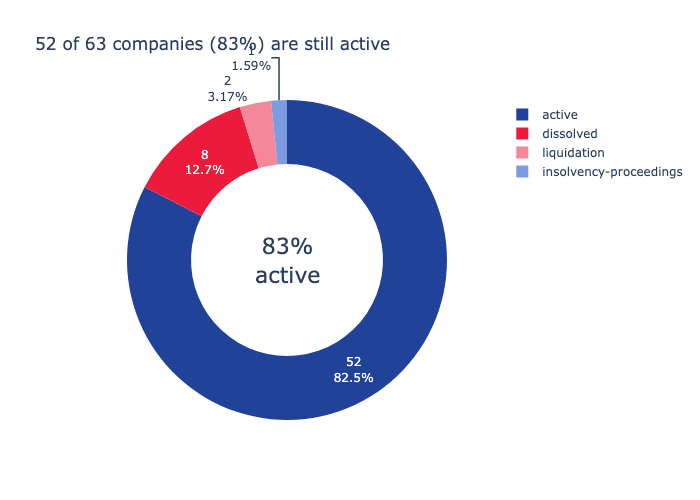

In [20]:
# Set a colour for each status
status_colours = {
    "active": BDO_BLUE,
    "dissolved": BDO_RED,
    "liquidation": RED_LIGHT,
    "insolvency-proceedings": BLUE_LIGHT,
}

# Share of companies that are active, shown in the centre of the donut
active_percent = status_counts["active"] / status_counts.sum() * 100

# hole=0.6 cuts out the middle 60% of the pie, which makes it a donut
# color_discrete_map gives each status its colour from status_colours
fig = px.pie(names=status_counts.index, values=status_counts.values, hole=0.6,
             color=status_counts.index, color_discrete_map=status_colours,
             title=f"{status_counts['active']} of {status_counts.sum()} companies ({active_percent:.0f}%) are still active")

# Keep the slices in order (largest first), draw them clockwise, and show each slice's count and percentage
fig.update_traces(sort=False, direction="clockwise", textinfo="value+percent")

# Show the active percentage in the centre; <br> starts a new line in plotly text
fig.add_annotation(text=f"{active_percent:.0f}%<br>active", showarrow=False, font_size=22)
fig.show()

**Finding:**
- **52 of 63 companies (83%) are still active.** 8 are dissolved, 2 are in liquidation and 1 is in insolvency proceedings.
- The sample is therefore mainly made up of active companies, with 11 no longer active. This gives a group of non-active companies that the active companies can be compared with.

## 3.3 Size

There is no turnover column, so I looked at the two fields that can hint at size and structure: the type of the last accounts filed, and the company type.

In [21]:
print("Type of the last accounts filed")
# dropna=False also counts the blanks
accounts_counts = df_prof_clean["last_accounts_type"].value_counts(dropna=False)
display(accounts_counts.to_frame())

print("Company type")
display(df_prof_clean["company_type"].value_counts(dropna=False).to_frame())

Type of the last accounts filed


,count
last_accounts_type,
full,33
group,22
small,3
total-exemption-full,2
audit-exemption-subsidiary,2
interim,1


Company type


,count
company_type,
ltd,43
plc,9
private-limited-guarant-nsc,7
private-limited-shares-section-30-exemption,2
private-limited-guarant-nsc-limited-exemption,2


**Finding:**

- **55 of the 63 companies (87%)** file `full` (33) or `group` (22) accounts. The other 8 file `small` (3), `total-exemption-full` (2), `audit-exemption-subsidiary` (2) or `interim` (1) accounts. Smaller companies can file simpler accounts, so full and group accounts may point to larger companies.
- **Most companies are private companies limited by shares (43 of 63).** There are also 9 public limited companies (`plc`), 9 companies limited by guarantee (7 `private-limited-guarant-nsc` and 2 `private-limited-guarant-nsc-limited-exemption`) and 2 companies limited by shares but exempt from using "Limited" in their name (`private-limited-shares-section-30-exemption`).

**Decision:** Accounts type is the closest field to a size measure, so full or group accounts are a reasonable first filter for BDO’s mid-market focus, although it isn't a direct measure of size. Legal form doesn't measure size either, but it hints at which BDO team might be relevant: private companies fit BDO's core mid-market work, a plc can include listed and very large companies, and companies limited by guarantee are often charities, schools or membership bodies, which BDO's not-for-profit team serves.

## 3.4 Location

The registered office postcode has no blanks, so it is the most reliable location field. I took the letters at the start of each postcode (the postcode area) and flagged the London areas.

In [22]:
# Postcode area = the letters at the start of the postcode, e.g. "EC" from "EC2V 7JE"
def get_postcode_area(postcode):
    area = ""
    for character in postcode:
        if character.isalpha():  # still a letter, so keep it
            area = area + character
        else:  # first digit reached, so stop
            break
    return area

# apply() runs the function on every postcode
df_prof_clean["postcode_area"] = df_prof_clean["registered_office_address_postal_code"].apply(get_postcode_area)

# London postcode areas
london_areas = ["EC", "WC", "E", "N", "NW", "SE", "SW", "W"]
df_prof_clean["in_london"] = df_prof_clean["postcode_area"].isin(london_areas)

print("Blank postcodes:", df_prof_clean["registered_office_address_postal_code"].isna().sum())
print("Companies with a London registered office:", df_prof_clean["in_london"].sum(), "of", len(df_prof_clean))
print()
print("Postcode areas:")
area_counts = df_prof_clean["postcode_area"].value_counts()
display(area_counts.head(15).to_frame().T)

Blank postcodes: 0
Companies with a London registered office: 23 of 63

Postcode areas:


postcode_area,EC,B,W,L,LS,SO,E,DE,SW,SG,CH,HP,BN,GL,TS
count,13,5,5,3,3,2,2,2,2,2,1,1,1,1,1


**Finding:**
- No postcodes are missing, making postcode area a complete field for analysing registered office locations.
- **23 of 63 companies (37%) have a London registered office**, with **13 located in EC alone (the City of London)**.
- Outside London, companies are spread across several areas, with smaller clusters in Birmingham (B, 5), Liverpool (L, 3) and Leeds (LS, 3).

**Limitation:** A registered office doesn't always show where a company actually operates, as some businesses use an accountant's or law firm's address.

## 3.5 Sector

The industry columns are stored as text that looks like a list, for example `[50200,64209,70100]`, and a company can have up to four codes. So I first counted how many SIC codes each company has.

In [23]:
# Remove square brackets from the SIC codes
df_prof_clean["sic_codes_clean"] = df_prof_clean["sic_codes"].str.strip("[]")

# Split the codes into a list for each company
df_prof_clean["sic_list"] = df_prof_clean["sic_codes_clean"].str.split(",")

# How many codes each company has
df_prof_clean["number_of_sic_codes"] = df_prof_clean["sic_list"].apply(len)

display(
    df_prof_clean["number_of_sic_codes"]
    .value_counts()
    .sort_index()
    .to_frame()
)

,count
number_of_sic_codes,
1,46
2,3
3,10
4,4


**Finding:** Most companies in the sample have only one recorded SIC code. Of the 63 companies, 46 (73%) have one code, 3 have two, 10 have three and 4 have four, so 17 companies (27%) have more than one recorded business activity.

Before using the codes, I checked that every SIC code is valid: a valid code has exactly 5 digits. I then removed any invalid code from `sic_list`, so that only valid codes are used from this point on.

In [24]:
# A valid SIC code is exactly 5 digits, so collect any that aren't
invalid_rows = []

for i in range(len(df_prof_clean)):

    company_number = df_prof_clean.loc[i, "company_number"]
    company_name = df_prof_clean.loc[i, "company_name"]
    sic_list = df_prof_clean.loc[i, "sic_list"]

    # Look at each of the company's codes
    for code in sic_list:

        code = str(code).strip()

        # Not 5 characters long, or not all digits, so it's invalid
        if len(code) != 5 or not code.isdigit():
            invalid_rows.append([company_number, company_name, code])

# Turn the list into a table
invalid_codes = pd.DataFrame(
    invalid_rows,
    columns=["company_number", "company_name", "invalid_code"]
)

# Show the invalid codes, if there are any
if len(invalid_codes) == 0:
    print("All SIC codes contain exactly 5 digits.")
else:
    display(invalid_codes)

# Keep only the valid codes, so only 5-digit codes are used from here on
valid_sic_lists = []
for sic_list in df_prof_clean["sic_list"]:
    valid_codes = []
    for code in sic_list:
        code = str(code).strip()
        if len(code) == 5 and code.isdigit():
            valid_codes.append(code)
    valid_sic_lists.append(valid_codes)

df_prof_clean["sic_list"] = valid_sic_lists

# Recount the codes now that only valid ones are left
df_prof_clean["number_of_sic_codes"] = df_prof_clean["sic_list"].apply(len)
print("Companies by number of valid SIC codes:")
display(
    df_prof_clean["number_of_sic_codes"]
    .value_counts()
    .sort_index()
    .to_frame()
)

,company_number,company_name,invalid_code
0,37516,LUPFAWJHB LIMITED,1721
1,7633,WILLIAM SINCLAIR HORTICULTURE LIMITED,8990
2,9725,THE REAL HOTEL COMPANY LIMITED,5510


Companies by number of valid SIC codes:


,count
number_of_sic_codes,
0,2
1,44
2,4
3,9
4,4


**Finding:** 3 SIC codes are invalid because they have only four digits: `1721` (Lupfawjhb), `8990` (William Sinclair Horticulture) and `5510` (The Real Hotel Company). `1721` and `5510` are labelled "Invalid Code" in `sic_code_descriptions`. `8990` is described as "Other mining and quarrying n.e.c.", which is code `08990`, so it lost its leading zero.

**Decision:** All three companies are dissolved, so rather than repair `08990` I removed all 3 codes. After the removal, **44 companies have exactly one valid code, 17 have more than one and 2 have none**.

I then looked at the industries in three steps: first the companies with only one SIC code, whose sector is clear; then the companies with several codes; and finally every code, split by whether it comes from a company with one code or several.

In [25]:
# The first two digits of a SIC code (the "division") decide the broad sector, using the SIC 2007 groupings
# Each sector is given the range of divisions it covers, e.g. range(64, 67) is 64, 65 and 66
sector_divisions = {
    "Agriculture, forestry and fishing": range(1, 4),
    "Mining and quarrying": range(5, 10),
    "Manufacturing": range(10, 34),
    "Energy, water and waste": range(35, 40),
    "Construction": range(41, 44),
    "Wholesale and retail": range(45, 48),
    "Transport and storage": range(49, 54),
    "Hotels and food": range(55, 57),
    "Information and communication": range(58, 64),
    "Finance and insurance": range(64, 67),
    "Real estate": range(68, 69),
    "Professional, scientific and technical": range(69, 76),
    "Administrative and support": range(77, 83),
    "Public administration": range(84, 85),
    "Education": range(85, 86),
    "Health and social work": range(86, 89),
    "Arts, sport and recreation": range(90, 94),
}

# Flip it into a lookup from each division to its sector, e.g. 64 -> "Finance and insurance"
division_to_sector = {}
for sector_name, divisions in sector_divisions.items():
    for division in divisions:
        division_to_sector[division] = sector_name

# Function: turn a SIC code into a broad sector
def sic_to_sector(code):
    if code == "99999":
        return "Dormant company"
    division = int(code[:2])  # first two digits as a number
    return division_to_sector.get(division, "Other services")  # any division not in the dictionary is "Other services"

# Give every company a sector label from all of its valid codes:
# a company with one code gets its one sector; a company with several gets every sector its codes fall in
sector_labels = []
for sic_list in df_prof_clean["sic_list"]:
    company_sectors = []
    for code in sic_list:
        sector = sic_to_sector(code)
        # List each sector only once, even if several of the company's codes fall in it
        if sector not in company_sectors:
            company_sectors.append(sector)
    if len(company_sectors) == 0:
        sector_labels.append("Unknown (no valid SIC code)")
    else:
        # "; ".join puts the sectors into one piece of text, separated by "; "
        sector_labels.append("; ".join(company_sectors))

df_prof_clean["sector"] = sector_labels

# Sector profile: only companies with exactly one valid SIC code, so each company's sector is clear
single_code = df_prof_clean[df_prof_clean["number_of_sic_codes"] == 1]
sector_counts = single_code["sector"].value_counts()

print("Broad sector of companies with exactly one valid SIC code")
display(sector_counts.to_frame().T)

# Check how many companies have been assigned a sector
print(f"Companies assigned a sector: {sector_counts.sum()} out of {len(single_code)}")

Broad sector of companies with exactly one valid SIC code


sector,Finance and insurance,"Professional, scientific and technical",Other services,Wholesale and retail,Manufacturing,"Arts, sport and recreation",Dormant company,Health and social work,Administrative and support,Real estate,Construction,Information and communication
count,14,6,6,3,3,2,2,2,2,2,1,1


Companies assigned a sector: 44 out of 44


The count above leaves out the 17 companies with more than one code. Next, I looked at those 17 companies on their own: for each sector, how many of them have at least one SIC code in it. Each company counts only once per sector, but it can count towards more than one sector.

In [26]:
# Companies with more than one valid SIC code
multi_code = df_prof_clean[df_prof_clean["number_of_sic_codes"] > 1]

# Count the companies with at least one code in each sector
multi_sector_counts = {}

for sic_list in multi_code["sic_list"]:
    # List the company's sectors, each only once, so a company is counted once per sector
    company_sectors = []
    for code in sic_list:
        sector = sic_to_sector(code)
        if sector not in company_sectors:
            company_sectors.append(sector)

    for sector in company_sectors:
        if sector in multi_sector_counts:
            multi_sector_counts[sector] += 1
        else:
            multi_sector_counts[sector] = 1

# Turn the dictionary into a pandas Series, sorted from the highest count to the lowest
multi_sector_counts = pd.Series(multi_sector_counts).sort_values(ascending=False)

print("Multi-code companies:", len(multi_code))
print("Companies with at least one SIC code in each sector (each company counted once per sector)")
display(multi_sector_counts.to_frame("companies").T)

# A company can be in several sectors, so the counts add up to more than the number of companies
print("Total across sectors:", multi_sector_counts.sum(), "| distinct companies:", len(multi_code))

Multi-code companies: 17
Companies with at least one SIC code in each sector (each company counted once per sector)


,Manufacturing,Hotels and food,Real estate,Wholesale and retail,"Professional, scientific and technical","Arts, sport and recreation",Administrative and support,Education,Transport and storage,Finance and insurance,Mining and quarrying,"Energy, water and waste",Other services,Information and communication,Construction,Health and social work
companies,6,3,3,3,2,2,2,2,1,1,1,1,1,1,1,1


Total across sectors: 31 | distinct companies: 17


Finally, I counted every valid code across all companies, split into codes from companies with one SIC code and codes from companies with several, and charted them as a stacked bar. This shows in one chart where each sector's codes come from.

,single,multi,total
Manufacturing,3,15,18
Finance and insurance,14,1,15
Real estate,2,6,8
"Professional, scientific and technical",6,2,8
Wholesale and retail,3,4,7
Other services,6,1,7
Education,0,6,6
"Arts, sport and recreation",2,2,4
Administrative and support,2,2,4
Health and social work,2,2,4


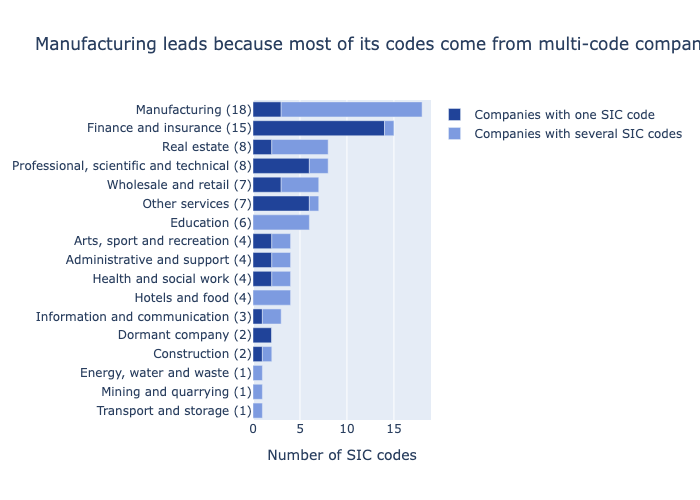

In [27]:
# Count codes per sector, split by whether the company has one code or several
single_counts = {}
multi_counts = {}

for sic_list in df_prof_clean["sic_list"]:
    for code in sic_list:
        sector = sic_to_sector(code)
        # .get(sector, 0) gives the count so far, or 0 if the sector isn't in the dictionary yet
        if len(sic_list) == 1:
            single_counts[sector] = single_counts.get(sector, 0) + 1
        else:
            multi_counts[sector] = multi_counts.get(sector, 0) + 1

# Put both counts in one table, largest total first
# fillna(0) puts 0 where a sector has no codes; astype(int) turns 3.0 into 3
sector_code_counts = pd.DataFrame({
    "single": pd.Series(single_counts),
    "multi": pd.Series(multi_counts),
})
sector_code_counts = sector_code_counts.fillna(0).astype(int)
sector_code_counts["total"] = sector_code_counts["single"] + sector_code_counts["multi"]
sector_code_counts = sector_code_counts.sort_values("total", ascending=False)
display(sector_code_counts)

# Rename the columns, as plotly uses the column names in the legend
chart_data = sector_code_counts.rename(columns={
    "single": "Companies with one SIC code",
    "multi": "Companies with several SIC codes",
})

# Add each sector's total to its name, e.g. "Manufacturing (18)"
sector_names = []
for sector in chart_data.index:
    total = chart_data.loc[sector, "total"]
    sector_names.append(f"{sector} ({total})")
chart_data.index = sector_names

# plotly draws the first row at the bottom, so sort smallest first to put the largest at the top
chart_data = chart_data.sort_values("total")

# px.bar stacks the two columns into one bar per sector
fig = px.bar(chart_data, x=["Companies with one SIC code", "Companies with several SIC codes"],
             y=chart_data.index, orientation="h",
             color_discrete_sequence=[BDO_BLUE, BLUE_LIGHT],
             title="Manufacturing leads because most of its codes come from multi-code companies")

# Tidy the axis and legend titles
fig.update_layout(yaxis_title=None, xaxis_title="Number of SIC codes", legend_title=None)
fig.show()

**Finding:**

- **Among the 44 companies with one valid SIC code, finance and insurance is the largest sector**, accounting for 14 companies (32%). Manufacturing accounts for only 3 companies.
- **Among the 17 companies with multiple SIC codes, manufacturing is the most common sector**, appearing in 6 companies (35%). Hotels and food, real estate, and wholesale and retail each appear in 3 companies.
- **When every valid SIC code is counted, manufacturing ranks first**, with 18 codes, followed by finance and insurance with 15.
- **The split explains the change in ranking.** Only 3 of manufacturing's 18 codes come from single-code companies; the other 15 come from 6 companies with several codes. Finance and insurance is the opposite: 14 of its 15 codes come from single-code companies.

**Decision:** Counting only single-code companies would understate manufacturing, so the `sector` column keeps every sector a company's valid codes fall in, rather than picking one.

## 3.6 Metrics considered but not explored

I also considered these metrics, but this data wasn't reliable enough to use them.

| Potential metric | Why it could be useful | Reason for exclusion or limitation |
|---|---|---|
| Officer turnover | Changes in company leadership could provide useful business context. | The officers sheet holds only about 7% of the officers in the Companies House totals (2.4.1). Resignation counts alone also do not show when or why changes occurred, making turnover difficult to interpret reliably. |
| Revenue and employee count | Would provide a more direct measure of company size and help assess whether companies fit BDO's mid-market focus. | Comparable revenue and employee data were not available in the dataset, so accounts type is the closest available proxy for size (3.3). |
| Filing behaviour over time | Changes in filing patterns could help identify developments in a company's circumstances. | Current filing flags do not establish when a problem began or whether filing behaviour changed over time. A more detailed filing history would be needed. |
| Changes in outstanding charges over time | Could provide context about changes in a company's secured borrowing. | The charges sheet holds only about 54% of the charges in the Companies House totals (2.4.1), limiting the reliability of comparisons over time. |

With this picture of the sample, I used the same fields to look for companies BDO could approach.

# 4 Prospecting: Who could BDO approach?

The aim is to narrow the 63 companies down to a shortlist of companies that may fit BDO's services and its mid-market focus, in three stages followed by a final shortlist:

- **Size:** Which active companies file accounts that suggest a larger company?
- **Type of organisation:** Which BDO services or teams might be relevant to each company?
- **Location:** Is each company better aligned with the London office or a regional office?
- **Shortlist:** Which companies pass all three?

**Terms used from here on:** I call the companies that pass the size stage (active and filing full or group accounts) **prospects**, and the prospects that pass every stage **the shortlist**.

**Limitation:** There is **no revenue column**, so I couldn't check companies against BDO's £10m to £500m mid-market definition. The shortlist is a list of companies to research, not confirmed targets.

**Officers data:** I left the officers sheet out of prospecting, because only about 7% of the officer records are included (2.4.1).

## 4.1 Size: active companies that file full or group accounts

**Method:** I first kept the 52 active companies, as companies that are dissolved, in liquidation or in insolvency proceedings are unlikely to become new clients. I then narrowed these to the 46 companies whose latest accounts type is `full` or `group`.

In [28]:
# Step 1: keep the companies that are still trading
active_companies = df_prof_clean[df_prof_clean["company_status"] == "active"]

# Step 2: keep the ones filing full or group accounts (my closest sign of a larger company)
# .copy() makes a separate table, so I can add new columns to it later
full_or_group = active_companies["last_accounts_type"].isin(["full", "group"])
prospects = active_companies[full_or_group].copy()

print("All companies:", len(df_prof_clean))
print("Active companies:", len(active_companies))
print("Active companies filing full or group accounts:", len(prospects))
print()

print("The active companies I left out, and their accounts type:")
left_out = active_companies[~full_or_group]
display(left_out[["company_name", "last_accounts_type", "sector"]])

# Show the prospects as a table, in alphabetical order and numbered from 1
print("The prospects:")
prospects_table = prospects[["company_name", "last_accounts_type", "sector"]]
prospects_table = prospects_table.sort_values("company_name").reset_index(drop=True)
prospects_table.index = prospects_table.index + 1
display(prospects_table)

All companies: 63
Active companies: 52
Active companies filing full or group accounts: 46

The active companies I left out, and their accounts type:


,company_name,last_accounts_type,sector
16,HAMPSHIRE CHAMBER OF COMMERCE,small,Administrative and support; Other services
35,CRAVEN DUNNILL & CO.LIMITED,small,Wholesale and retail
41,CHINA NAVIGATION COMPANY LIMITED(THE),audit-exemption-subsidiary,Finance and insurance
42,KENTSTONE PROPERTIES LIMITED,small,Real estate
55,JPMORGAN AMERICAN INVESTMENT TRUST PLC,interim,Finance and insurance
58,ATALANTA INVESTMENTS LIMITED,total-exemption-full,"Professional, scientific and technical"


The prospects:


,company_name,last_accounts_type,sector
1,B BRAUN STERILOG (YORKSHIRE) LIMITED,full,Health and social work
2,BA (GI) LIMITED,full,Finance and insurance
3,BARNARDO'S,group,Health and social work
4,BERTHON BOAT COMPANY LIMITED,group,Manufacturing
5,BIBBY MARINE LIMITED,group,"Transport and storage; Finance and insurance; Professional, scientific and technical"
6,BIRMINGHAM CITY FOOTBALL CLUB LIMITED,full,"Arts, sport and recreation"
7,BRITISH DENTAL ASSOCIATION,group,Other services
8,CHESTER DIOCESAN BOARD OF FINANCE,full,Other services
9,CHESTER RACE COMPANY LIMITED,group,"Hotels and food; Arts, sport and recreation"
10,CHURCH EXTENSION ASSOCIATION(INCORPORATED)(THE),full,Other services


**Finding:** 52 of the 63 companies are active, and **46 of those file full or group accounts**. These 46 are the prospects. The 6 active companies left out filed as `small`, `total-exemption-full`, `audit-exemption-subsidiary` or `interim` accounts.

**Limitation:** Accounts type is only a rough proxy for size, because there is no revenue data. It does **not** tell me whether a company is within BDO's £10m to £500m mid-market: the 46 include HSBC Bank and Lloyds Bank, which are widely known to be far above it, and JPMorgan American Investment Trust is left out only because its latest filing is an interim one.

## 4.2 Type of organisation: which BDO team might each prospect fit?

**Method:** I gave each prospect a rough organisation type using its legal form, name and SIC codes. The categories were private company, public company, investment trust and not-for-profit.

In [29]:
# Give each prospect a rough organisation type, based on its legal form, name and SIC codes
organisation_types = []

# iterrows() gives each row's index and its values; I only need the values
for index, row in prospects.iterrows():

    company_type = row["company_type"]
    name = row["company_name"]
    sic_list = row["sic_list"]

    # Guarantee and section-30 companies are often charities, schools or membership bodies
    if "guarant" in company_type or "section-30" in company_type:
        organisation_types.append("(Potential) not-for-profit")

    # 64301 is the SIC code for investment trusts, and some have "TRUST PLC" in their name
    elif "64301" in sic_list or "TRUST PLC" in name:
        organisation_types.append("(Potential) investment trust")

    # plc = public company
    elif company_type == "plc":
        organisation_types.append("Public company (plc)")

    # ltd = private company
    elif company_type == "ltd":
        organisation_types.append("Private company (ltd)")

    # Anything my rules don't cover, so I'd check it by hand
    else:
        organisation_types.append("Needs review")

# Add the labels as a new column
prospects["organisation_type"] = organisation_types

# How many prospects of each type
organisation_counts = prospects["organisation_type"].value_counts()
display(organisation_counts.to_frame("Number of companies"))

# The prospects that are not private companies, and what type each is
not_private = prospects[prospects["organisation_type"] != "Private company (ltd)"]
display(not_private[["company_name", "organisation_type"]])

,Number of companies
organisation_type,
Private company (ltd),28
(Potential) not-for-profit,10
Public company (plc),4
(Potential) investment trust,4


,company_name,organisation_type
12,SAMUEL HEATH AND SONS PUBLIC LIMITED COMPANY,Public company (plc)
15,THE BANKERS INVESTMENT TRUST PLC,(Potential) investment trust
17,CLIFTON HIGH SCHOOL,(Potential) not-for-profit
19,CHURCH EXTENSION ASSOCIATION(INCORPORATED)(THE),(Potential) not-for-profit
20,THE GLOBAL SMALLER COMPANIES TRUST PLC,(Potential) investment trust
21,LONDON STEAM SHIP OWNERS' MUTUAL INSURANCE ASSOCIATION LIMITED,(Potential) not-for-profit
22,HSBC BANK PLC,Public company (plc)
23,EAST LANCASHIRE CHAMBER OF COMMERCE AND INDUSTRY,(Potential) not-for-profit
24,BARNARDO'S,(Potential) not-for-profit
25,PENRITH FARMERS AND KIDDS PUBLIC LIMITED COMPANY(THE),Public company (plc)


**Finding:** Of the 46 prospects, 28 (61%) were classified as private companies, 10 as potential not-for-profit organisations, 4 as public companies and 4 as potential investment trusts.

**Why I took private companies forward:** BDO's main clients are mid-market businesses (1.5), and private companies are the largest group of prospects, so I took them forward as the main list for prospecting. The other groups are not ruled out; they suit different BDO teams or need a different check first:

- **Not-for-profit (10):** schools, charities, chambers of commerce and membership bodies, which BDO's specialist not-for-profit team serves (1.5).
- **Public companies (4):** two are HSBC Bank and Lloyds Bank, which are widely known to be far above BDO's £500m mid-market ceiling. The other two, Samuel Heath and Sons and Penrith Farmers and Kidds, may fit the mid-market and are worth checking separately.
- **Investment trusts (4):** listed investment funds run by fund managers rather than trading businesses, so they are a different kind of client from the mid-market companies this list is for.

**Limitation:** These labels come from legal form, name and SIC codes only, so they don't confirm a company's size, needs or fit with BDO.

## 4.3 Location: London or a regional office?

**Method:** I matched each company's registered postcode area to its nearest BDO office, then grouped the companies into London and regional.

In [30]:
# Postcode area -> nearest BDO office (my own judgement from a map, not how BDO splits its regions)
# Only the postcode areas that appear among the 46 prospects are listed
postcode_to_office = {
    "EC": "London", "W": "London", "E": "London", "SW": "London", "IG": "London", "RM": "London",
    "B": "Birmingham", "TF": "Birmingham",
    "BS": "Bristol", "GL": "Bristol", "NP": "Bristol",
    "PE": "Cambridge", "SG": "Cambridge",
    "BN": "Gatwick",
    "GU": "Guildford",
    "LS": "Leeds", "S": "Leeds", "DN": "Leeds", "TS": "Leeds",
    "L": "Liverpool", "CH": "Liverpool",
    "WA": "Manchester", "BB": "Manchester", "CA": "Manchester",
    "DE": "Nottingham", "NG": "Nottingham",
    "SL": "Reading",
    "SO": "Southampton",
}

# .map() looks up each postcode area in the dictionary; an area not in it would be left blank
prospects["bdo_office"] = prospects["postcode_area"].map(postcode_to_office)

# Start by marking every prospect as regional,
prospects["office_group"] = "Regional"
# then switch the London ones to London (.loc[rows, column] = value only changes those rows),
prospects.loc[prospects["bdo_office"] == "London", "office_group"] = "London"
# and mark any with no matching office as unmatched
prospects.loc[prospects["bdo_office"].isna(), "office_group"] = "Unmatched"

print("Prospects with no office matched:", prospects["bdo_office"].isna().sum())
display(prospects["office_group"].value_counts().to_frame())

Prospects with no office matched: 0


,count
office_group,
Regional,25
London,21


**Finding:** All 46 prospects were matched to a BDO office using the postcode-area lookup. Of these, **21 were assigned to London and 25 to regional offices**.

**Limitation:** The office match is my own judgement from postcode areas, not actual distances or how BDO allocates clients. A registered office can also be an accountant's or solicitor's address rather than where the company operates.

## 4.4 Shortlist: regional private companies

**Method:** I kept the prospects that are private companies matched to a regional office.

I focused on regional offices for two reasons: BDO's research shows the mid-market growing faster than the UK average in several regions (1.5), and a list for each regional office is something each office can act on. I did not analyse the London prospects further. They are not ruled out and could form a separate list for the London office.

In [31]:
# Shortlist = private companies nearest a regional office
regional_private = prospects[
    (prospects["organisation_type"] == "Private company (ltd)")
    & (prospects["office_group"] == "Regional")
]

# Sort by office, then by name
regional_private = regional_private.sort_values(["bdo_office", "company_name"])

# How many are left
print("Private companies assigned to regional offices:",len(regional_private),"of", len(prospects), "prospects")

# The shortlist, with the columns I care about
display(regional_private[["company_name", "bdo_office", "sector", "last_accounts_type"]])

Private companies assigned to regional offices: 19 of 46 prospects


,company_name,bdo_office,sector,last_accounts_type
3,BIRMINGHAM CITY FOOTBALL CLUB LIMITED,Birmingham,"Arts, sport and recreation",full
51,STADCO LIMITED,Birmingham,Manufacturing,full
7,GLOUCESTER RUGBY LIMITED,Bristol,"Arts, sport and recreation",full
33,NEWSQUEST COMMUNITY MEDIA LIMITED,Bristol,Information and communication,full
61,LAIRD LIMITED,Cambridge,"Professional, scientific and technical",full
54,UNITED LEARNING LTD,Cambridge,Real estate,group
6,DELTA LIMITED,Gatwick,"Professional, scientific and technical",full
45,CLEAN LINEN SERVICES LIMITED,Guildford,Other services,full
31,B BRAUN STERILOG (YORKSHIRE) LIMITED,Leeds,Health and social work,full
30,LEEDS CRICKET FOOTBALL AND ATHLETIC COMPANY LIMITED,Leeds,"Wholesale and retail; Hotels and food; Real estate; Arts, sport and recreation",full


I charted how each step narrows the 63 companies down to the shortlist.

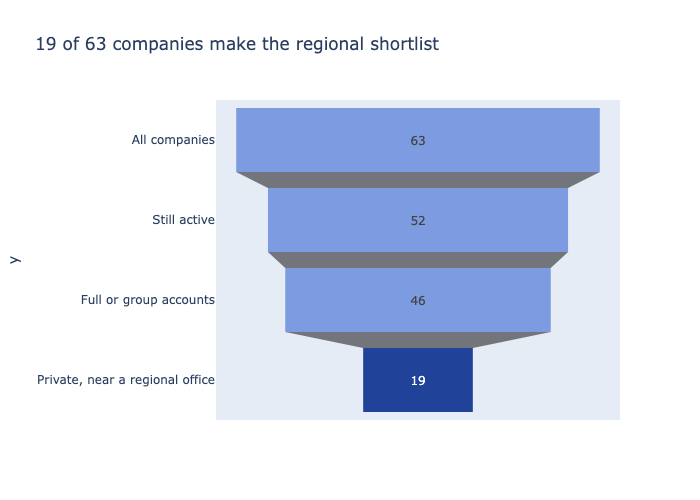

In [32]:
# How each step narrows the 63 companies down to the shortlist
steps = ["All companies", "Still active", "Full or group accounts", "Private, near a regional office"]
funnel_counts = [len(df_prof_clean), len(active_companies), len(prospects), len(regional_private)]

# px.funnel draws one centred bar per step, widest first, with each number on its bar
fig = px.funnel(x=funnel_counts, y=steps,
                title=f"{len(regional_private)} of {len(df_prof_clean)} companies make the regional shortlist")

# Light blue for each step, dark blue for the final shortlist
fig.update_traces(marker_color=[BLUE_LIGHT, BLUE_LIGHT, BLUE_LIGHT, BDO_BLUE])
fig.show()

**Finding:** 19 of the 46 prospects are private companies nearest a regional office, and form the shortlist. Leeds has the largest share (4 companies), while manufacturing is the most frequently represented sector, appearing in the SIC codes of 5 of the 19 companies.

**Next:** Each regional office could research these companies before approaching them.

**Limitation:** Before approaching anyone, BDO would need to check revenue, existing auditor relationships and whether the company is already a client. SIC codes also don't always reflect what a company actually does.

# 5 Risk: signals of distress and opportunity

Risk matters to BDO in two ways (1.5): an audit firm checks whether a prospective client is in financial difficulty, and the Business Restructuring team works with companies that are. I looked at three questions:

1. Do overdue filings or insolvency history distinguish **active** companies from **non-active** ones (dissolved, in liquidation or in insolvency proceedings)?
2. Do outstanding charges distinguish active from non-active companies?
3. Which active companies sit in sectors where BDO's own research points to possible service opportunities?

**Limitation:** Only 11 of the 63 companies are non-active, so this can show patterns in this sample but can't predict which companies will fail.

## 5.1 Overdue filings and insolvency history

**Method:** Late filing can be an early sign of trouble. I used the current Companies House fields `next_accounts_overdue` and `confirmation_statement_overdue`, rather than the deprecated `accounts_overdue` field. I kept blanks separate from 0, so a company only counts as not overdue when the data says so.

In [33]:
# Overdue, not overdue and blank, for each of the two current fields
# The flags are stored as 1 (overdue), 0 (not overdue) or blank
for field in ["next_accounts_overdue", "confirmation_statement_overdue"]:
    print(field, "| overdue:", (df_prof_clean[field] == 1).sum(),
          "| not overdue:", (df_prof_clean[field] == 0).sum(),
          "| blank:", df_prof_clean[field].isna().sum())
print()

blank_flags = df_prof_clean[df_prof_clean["next_accounts_overdue"].isna()]
print("Status of the companies with blank flags:", blank_flags["company_status"].value_counts().to_dict())
print()

# Blank flags are not counted as overdue, so these are only the confirmed cases
# | means "or", so a company is kept if either filing is overdue
accounts_late = df_prof_clean["next_accounts_overdue"] == 1
statement_late = df_prof_clean["confirmation_statement_overdue"] == 1
overdue = df_prof_clean[accounts_late | statement_late]
print("Companies with an overdue filing:", len(overdue), "of", len(df_prof_clean))

# Check whether companies with overdue filings have insolvency links
print("Companies with overdue filings and an insolvency link:", overdue["links_insolvency"].notna().sum())

display(overdue[["company_name", "company_status", "links_insolvency"]])

next_accounts_overdue | overdue: 3 | not overdue: 52 | blank: 8
confirmation_statement_overdue | overdue: 3 | not overdue: 52 | blank: 8

Status of the companies with blank flags: {'dissolved': 8}

Companies with an overdue filing: 3 of 63
Companies with overdue filings and an insolvency link: 1


,company_name,company_status,links_insolvency
8,THYSSENKRUPP BODY STAMPINGS LIMITED,liquidation,NaN
36,GREENE KING LEASING NO.1 LIMITED,liquidation,/company/00025090/insolvency
62,BLUE GROUP UK RETAIL LIMITED,insolvency-proceedings,NaN


**Finding:** All 3 companies with an overdue filing flag are already in liquidation or insolvency proceedings, and none of the active companies has one. The 8 blank flags belong to dissolved companies and were treated as unknown rather than overdue. Of the 3 companies with overdue flags, only 1 has a link in the current `links_insolvency` field.

**Limitation:** The flags show current filing status, not when a filing first became overdue, so filing history would be needed to see whether late filing gives an early warning. A missing insolvency link doesn't prove there's no insolvency record, and some records look older than others (2.7), so the flags should be checked against the live register.

## 5.2 Outstanding charges

**Method:** A charge is security given by a company to a lender. For each company, I calculated outstanding charges as its total charges minus those satisfied and part-satisfied, using the Companies House totals rather than counting rows, as decided in 2.4.1. One company has a blank part-satisfied count, which I treated as zero. I then compared the percentage of active and non-active companies with at least one outstanding charge.

**Limitation:** Only 3 of the non-active companies are in liquidation or insolvency proceedings (the rest are dissolved), too few to compare on their own. So this shows whether charges differ between active and non-active companies, not whether they predict insolvency.

In [34]:
# One set of charge totals per company (they repeat on every charge row) and treat any blank as 0
count_columns = ["total_count", "satisfied_count", "part_satisfied_count"]
charge_counts = (
    df_char_clean.groupby("company_number")[count_columns]
    .first()
    .fillna(0)
)
charge_counts["outstanding_charges"] = (
    charge_counts["total_count"]
    - charge_counts["satisfied_count"]
    - charge_counts["part_satisfied_count"]
)

# Attach the counts to each company, and flag the ones with an outstanding charge
companies_with_charges = df_prof_clean.merge(charge_counts, on="company_number")
companies_with_charges["has_outstanding"] = companies_with_charges["outstanding_charges"] > 0

# Active or not active (.loc[rows, column] = value only changes those rows)
companies_with_charges["status_group"] = "Not active"
companies_with_charges.loc[companies_with_charges["company_status"] == "active", "status_group"] = "Active"

# For each group: number of companies, number with an outstanding charge, and the percentage
# count() counts the companies in each group
# sum() adds up the True values (True = 1, False = 0), so it counts the companies with an outstanding charge
companies = companies_with_charges.groupby("status_group")["has_outstanding"].count()
with_outstanding = companies_with_charges.groupby("status_group")["has_outstanding"].sum()

comparison = pd.DataFrame({"companies": companies, "outstanding_charges": with_outstanding})
outstanding_share = comparison["outstanding_charges"] / comparison["companies"] * 100
comparison["outstanding_charges_percent"] = outstanding_share.round(0)
display(comparison)

,companies,outstanding_charges,outstanding_charges_percent
status_group,,,
Active,52,34,65.0
Not active,11,7,64.0


My outstanding-charge numbers come from the Companies House totals for each company, not from the individual charge rows. To test the calculation, I compared it with the charge rows for the companies whose rows are complete. For those companies, the two should agree exactly.

In [35]:
# Put the calculated count next to the real row counts for each company
charge_check = charge_counts.copy()
# Both are indexed by company number, so pandas lines the counts up by company
charge_check["row_count"] = df_char_clean.groupby("company_number").size()

# Count the rows marked outstanding for each company (0 if a company has none)
outstanding_charge_rows = df_char_clean[df_char_clean["status"] == "outstanding"]
charge_check["outstanding_rows"] = outstanding_charge_rows.groupby("company_number").size()
charge_check["outstanding_rows"] = charge_check["outstanding_rows"].fillna(0)

# Only companies with every charge in the sheet can be checked
fully_recorded = charge_check[charge_check["row_count"] == charge_check["total_count"]]

print("Companies whose charge rows match their Companies House total:", len(fully_recorded))
counts_match = fully_recorded["outstanding_rows"] == fully_recorded["outstanding_charges"]
print("Of these, outstanding counts that also match:", counts_match.sum(), "of", len(fully_recorded))

Companies whose charge rows match their Companies House total: 42
Of these, outstanding counts that also match: 42 of 42


**Finding:** For all 42 companies whose charge rows are complete, the number of rows marked outstanding equals the calculated count, so the calculation agrees with the charge records.

The chart compares the two groups.

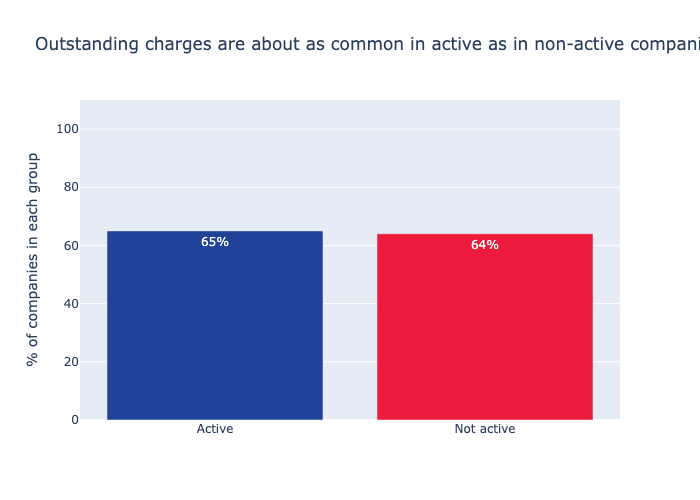

In [36]:
outstanding_percent = comparison["outstanding_charges_percent"]

# Turn each percentage into a label like "65%" to show on its bar
bar_labels = []
for value in outstanding_percent:
    bar_labels.append(f"{value:.0f}%")

# One bar per group, each with its percentage on it
fig = px.bar(x=outstanding_percent.index, y=outstanding_percent.values, text=bar_labels,
             color=outstanding_percent.index, color_discrete_sequence=[BDO_BLUE, BDO_RED],
             labels={"x": "", "y": "% of companies in each group"},
             title="Outstanding charges are about as common in active as in non-active companies")

# No legend needed, as each bar is already labelled; run the y-axis from 0 to 110 so the labels fit
fig.update_layout(showlegend=False, yaxis_range=[0, 110])
fig.show()

In [37]:
# Dissolved companies that still have an outstanding charge recorded
is_dissolved = companies_with_charges["company_status"] == "dissolved"
dissolved_outstanding = companies_with_charges[is_dissolved & companies_with_charges["has_outstanding"]]
print("Dissolved companies with an outstanding charge:", len(dissolved_outstanding))

Dissolved companies with an outstanding charge: 6


**Finding:** 34 of 52 active companies (65%) and 7 of 11 non-active companies (64%) have at least one outstanding charge. The proportions are almost identical, suggesting that outstanding charges do not distinguish active from non-active companies in this sample. I therefore did not use this indicator to prioritise the shortlist.

**Limitation:** A charge only shows that a lender holds security, not that a company is struggling. Six dissolved companies still have charges recorded as outstanding, but that doesn't confirm the debt is still unpaid.

## 5.3 External market signals and potential service opportunities

I combined BDO's sector research with Companies House SIC codes to identify active companies operating in sectors that may present service opportunities.

| Sector | External market signal | Potential service opportunity |
|---|---|---|
| Finance and insurance | [FraudTrack 2026](https://www.bdo.co.uk/en-gb/news/2026/bdos-fraudtrack-report-5-5bn-lost-to-fraud-in-2025) reports fraud losses of £171m in this sector, the largest of the three sectors it highlights (UK cases of £50,000 and above, December 2024 to November 2025). | Potential demand for fraud prevention, risk advisory and forensic services. |
| Sport (football) | BDO's [football finance report](https://www.bdo.co.uk/en-gb/news/2026/90-of-professional-football-clubs-expect-to-report-financial-losses-for-2025) found that 90% of clubs in the top four English professional leagues expect to report pre-tax trading losses for 2025. | Potential demand for restructuring, financial advisory and cost management. |
| Retail | BDO's [High Street Sales Tracker](https://www.bdo.co.uk/en-gb/news/2026/retailers-call-for-budget-support-as-september-sales-hit-seven-year-low) reports that September 2026 was the weakest September for total discretionary retail sales in seven years, excluding the pandemic period. | Potential demand for cash-flow support, restructuring and business advisory. |

The service opportunities are my reading of BDO's research, not known needs of these companies. The football report covers football clubs only, so it applies to other sports companies only indirectly.

**Method:** I flagged active companies with at least one valid SIC code in a researched sector (a company can match more than one). Sector definitions follow the [SIC 2007 codes listed by Companies House](https://resources.companieshouse.gov.uk/sic/):

- **Finance and insurance:** SIC divisions 64–66.
- **Retail:** SIC division 47 only; wholesale (46) and the sale and repair of motor vehicles (45) were excluded.
- **Sport:** SIC group 931 (sports facilities, sports clubs, fitness facilities, racehorse owners and other sports activities).

In [38]:
# True if any of the company's SIC codes starts with any of the prefixes
# prefixes is always a list, even for one prefix, e.g. ["47"]
def has_code(sic_list, prefixes):
    for code in sic_list:
        for prefix in prefixes:
            if code.startswith(prefix):
                return True
    return False

# Flag each company for the three researched sectors, one company at a time
finance_flags = []
retail_flags = []
sport_flags = []
for codes in df_prof_clean["sic_list"]:
    finance_flags.append(has_code(codes, ["64", "65", "66"]))
    retail_flags.append(has_code(codes, ["47"]))
    sport_flags.append(has_code(codes, ["931"]))

df_prof_clean["finance_sector"] = finance_flags
df_prof_clean["retail_sector"] = retail_flags
df_prof_clean["sport_sector"] = sport_flags
# | means "or", so this is True if the company matches any of the three sectors
df_prof_clean["any_flagged_sector"] = (
    df_prof_clean["finance_sector"]
    | df_prof_clean["retail_sector"]
    | df_prof_clean["sport_sector"]
)

# Count the matches among active companies (a company can match more than one sector)
# Filter the active companies again, so they include the new sector columns
active_companies = df_prof_clean[df_prof_clean["company_status"] == "active"]
print("Active companies:", len(active_companies))
sector_columns = ["finance_sector", "retail_sector", "sport_sector", "any_flagged_sector"]
display(active_companies[sector_columns].sum())

Active companies: 52


finance_sector        15
retail_sector          1
sport_sector           4
any_flagged_sector    19
dtype: int64

**Finding:** 19 of 52 active companies have at least one SIC code in a researched sector: 15 in finance and insurance, 4 in sport and 1 in retail (one company matches both retail and sport). Based on BDO's research, these could be worth a look for fraud and forensic services (finance and insurance), restructuring and financial advice (sport), and cost management or restructuring advice (retail).

**Limitation:** SIC codes show a company's registered activities, which may not be its main business. Some finance companies may be holding companies rather than financial services firms, and retail only covers division 47, so wholesale and motor trade are left out.

# 6 Shortlisted regional companies with opportunity indicators
**Method:** I checked which of the 19 shortlisted companies have a SIC code in one of the researched sectors.

I left out outstanding charges, as they were almost equally common in active and non-active companies (5.2).

In [39]:
# Add each shortlisted company's sector flags (from 5.3) to the shortlist
flag_columns = ["company_number", "sic_list", "finance_sector", "retail_sector", "sport_sector", "any_flagged_sector"]
sector_flags = df_prof_clean[flag_columns]

shortlist = regional_private[["company_number", "company_name", "bdo_office"]]
shortlist = shortlist.merge(sector_flags, on="company_number")

# Keep the shortlisted companies that match at least one researched sector
sector_matches = shortlist[shortlist["any_flagged_sector"]]

print("Shortlisted companies matching at least one sector:", len(sector_matches), "of", len(shortlist))
columns_to_show = ["company_name", "bdo_office", "sic_list", "finance_sector", "retail_sector", "sport_sector"]
display(sector_matches[columns_to_show])

Shortlisted companies matching at least one sector: 5 of 19


,company_name,bdo_office,sic_list,finance_sector,retail_sector,sport_sector
0,BIRMINGHAM CITY FOOTBALL CLUB LIMITED,Birmingham,[93120],False,False,True
2,GLOUCESTER RUGBY LIMITED,Bristol,[93120],False,False,True
9,LEEDS CRICKET FOOTBALL AND ATHLETIC COMPANY LIMITED,Leeds,"[47710, 55100, 68209, 93110]",False,True,True
12,BIBBY MARINE LIMITED,Liverpool,"[50200, 64209, 70100]",True,False,False
13,CHESTER RACE COMPANY LIMITED,Liverpool,"[55100, 56210, 93110]",False,False,True


**Finding:** 5 of the 19 shortlisted companies match at least one researched sector. Birmingham City Football Club, Gloucester Rugby and Chester Race Company match sport; Leeds Cricket Football and Athletic matches both retail and sport; and Bibby Marine matches finance and insurance, but only through a holding-company code (`64209`, activities of other holding companies).

**Limitation:** The other 14 don't match a researched sector, but that doesn't make them weaker prospects: the data has no financial information to judge their needs.

# 7 Techniques I used and what I would do next

**Used:**
- **Background research** on BDO before analysing, so each question links to a BDO service (1.5).
- **Data dictionary:** matching every column to the Companies House API documentation.
- **Data quality checks:** how the sheets link, exact and conflicting duplicates (resolved against the Companies House register), completeness, data types and the age of the data.
- **Cross-checks:** row counts against the Companies House totals, and my outstanding-charge calculation against the charge rows for 42 companies.
- **Charts:** plotly in BDO's colours, with titles that state the finding.

**Ideas I set aside**:
- **Timing:** using each company's year-end month to decide when to approach it, as audit work is planned around year-ends.
- **Recent borrowing:** treating newly registered charges as a sign of refinancing or a deal, which is relevant to BDO's Deals team.
- **Leadership changes:** using the appointment and resignation dates in the officers sheet to spot companies with recent director changes, which can be a moment when a company reviews its advisers. (I set this aside because the officers sheet holds only about 7% of the officer records in the Companies House totals 2.4.1).

**Would consider:**
- **A fresh and full data pull** from the Companies House API, within its limit of 600 requests per 5 minutes, to get the complete officer and charge records.
- **A pipeline** that downloads, cleans and checks fresh data automatically, storing the date each record was taken.
- **Revenue data** to apply BDO's £10m to £500m definition properly.

# 8 Other data I would use alongside this

- **Company financials:** turnover, profit and employee numbers, from filed accounts or a trusted external database. Revenue is the key filter for BDO's mid-market, and this data doesn't have it.
- **The Gazette:** official insolvency notices, such as winding-up orders, to confirm and date insolvency events.
- **BDO's own client and Customer Relationship Management (CRM) data:** to separate existing clients from prospects.
- **A wider, random sample from the Companies House bulk data:** so findings can be applied to UK companies in general, not just the oldest ones.